# Crear peligro antes del tiro · Liga F 2023/24

**Línea de pase** · Ángel Marqueta Alonso · Investigación exploratoria.

La pregunta es quién desplaza el balón a lugares desde los que el modelo espera más peligro. No buscamos una nota universal de calidad. Usamos la temporada histórica acordada, no 2026/27.

Este cuaderno reproduce preparación, ajuste, valoración cruzada y tablas a partir de los módulos `.py`. Los eventos originales quedan en una caché privada por las restricciones del acuerdo de StatsBomb. El comando `codigo/ejecutar.py` genera además todas las figuras y el informe.


In [1]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

RAIZ = Path.cwd().parent if Path.cwd().name == 'cuadernos' else Path.cwd()
assert (RAIZ / 'codigo').exists(), 'Abrir desde la carpeta del estudio o cuadernos/'
sys.path.insert(0, str(RAIZ / 'codigo'))
from datos import obtener_temporada, preparar
from modelo import ajustar, validacion_cruzada, resumir, celdas
CACHE = Path(os.environ.get('LINEA_CACHE', RAIZ / 'datos/privados'))


## 1. Cobertura y calidad

Descargamos eventos y alineaciones de los 240 encuentros, fijando el commit del proveedor. Cada equipo debe tener 30 partidos. Revisamos identificadores, coordenadas y minutos. La definición de juego abierto es conservadora: `Regular Play`, sin pases de reinicio y tiros `Open Play`.

Se detectaron intervalos posicionales invertidos. No se usan para calcular minutos: el denominador se reconstruye con el once inicial, las sustituciones y las expulsiones. Se trunca el descuento; las ausencias médicas temporales no se descuentan. Las jugadoras que entran en descuento pueden tener acciones y cero minutos reglamentarios, por lo que se excluyen de las tasas.


In [2]:
partidos, archivos, manifiesto = obtener_temporada(CACHE)
acciones, minutos, auditoria = preparar(partidos, archivos)
display(auditoria.drop(columns=['partido_id', 'fecha', 'jornada']).sum().to_frame('recuento'))
assert len(partidos) == 240
assert not acciones.evento_id.duplicated().any()
assert minutos.groupby(['partido_id','equipo']).minutos.sum().max() <= 990.01


,recuento
eventos,835429
duplicados,0
sin_coordenadas,0
coordenadas_invalidas,0
acciones_seleccionadas,168296
intervalos_posicion_invertidos,1


## 2. La superficie de valor

Dividimos las coordenadas StatsBomb (120×80, no metros) en 12×8 celdas. Todos los equipos atacan hacia x=120 en este sistema.

Para cada celda i:

- N(i): tiros y movimientos intentados.
- r(i): goles observados / N(i).
- Q(i,j): movimientos completados de i a j / N(i).

Resolvemos **V = r + QV** por iteración. Un pase fallido no transfiere valor a otra celda. No usamos el xG del proveedor y no estimamos una probabilidad calibrada de gol de una posesión real. El modelo simplifica las acciones y no representa todos los posibles finales de posesión.

La puntuación principal de una acción completada es **V(destino) − V(origen)**. Las diferencias negativas se conservan; no es lo mismo que sumar solo valores positivos. Los fallos valen cero en ese criterio; el diagnóstico alternativo resta V(origen) a los pases fallidos. Las conducciones son eventos de desplazamiento, no intentos de regate.


In [3]:
modelo = ajustar(acciones)
display(pd.Series({k:modelo[k] for k in ['nx','ny','iteraciones','error','celdas_vacias']}))
assert np.isfinite(modelo['valor']).all()
assert np.max(modelo['valor']) <= 1
assert np.max(np.abs(modelo['valor'] - modelo['q'] @ modelo['valor'] -
    np.bincount(celdas(acciones.x,acciones.y)[acciones.gol], minlength=96) /
    np.maximum(modelo['total'],1))) < 1e-9


nx               1.200000e+01
ny               8.000000e+00
iteraciones      1.340000e+02
error            9.109732e-11
celdas_vacias    0.000000e+00
dtype: float64

## 3. Valorar fuera del partido de entrenamiento

Separamos los partidos en cinco grupos con semilla fija. Cada uno se valora con un modelo que solo vio los otros 192 partidos. La partición aleatoria permite una comparación retrospectiva: no es una evaluación de predicción futura. Los partidos del mismo equipo siguen relacionados.


In [4]:
puntos, pliegues = validacion_cruzada(acciones)
display(pd.DataFrame(pliegues).drop(columns='ids_evaluacion'))
assert len(puntos) == acciones.tipo.ne('Shot').sum()
assert not puntos.evento_id.duplicated().any()


,pliegue,partidos_entrenamiento,partidos_evaluacion,iteraciones,error,celdas_vacias
0,0,192,48,136,9.852317e-11,0
1,1,192,48,134,8.865623e-11,0
2,2,192,48,134,8.864834e-11,0
3,3,192,48,134,9.220408e-11,0
4,4,192,48,132,8.732416e-11,0


## 4. Minutos, clasificación e incertidumbre

Sumamos por jugadora y equipo, dividimos por minutos y multiplicamos por 90. Exigimos 900 minutos. Las 1.000 remuestras bootstrap reutilizan partidos de cada jugadora con reemplazo y recalculan el cociente de sumas. Condicionan el modelo ya ajustado: no abarcan su incertidumbre, la selección de las primeras posiciones ni toda la dependencia del calendario.


In [5]:
ranking, por_partido = resumir(puntos, minutos)
elegibles = ranking[ranking.elegible_900]
columnas = ['jugadora','equipo','minutos','xt_neto_90','ic95_inferior','ic95_superior']
display(elegibles[columnas].head(15).round(3))
exportado = pd.read_csv(RAIZ / 'datos/salida/jugadoras_xt.csv')
a = ranking.sort_values(['jugadora_id','equipo'])
b = exportado.sort_values(['jugadora_id','equipo'])
np.testing.assert_allclose(a.xt_neto_90,b.xt_neto_90,rtol=1e-10,atol=1e-12)


,jugadora,equipo,minutos,xt_neto_90,ic95_inferior,ic95_superior
17,Caroline Graham Hansen,Barcelona WFC,1673.043,0.593,0.488,0.714
11,Mariona Caldentey,Barcelona WFC,1505.091,0.251,0.167,0.346
20,Patri Guijarro,Barcelona WFC,1721.165,0.231,0.170,0.301
12,Irene Paredes,Barcelona WFC,1306.280,0.210,0.136,0.307
19,Aitana Bonmati,Barcelona WFC,1633.914,0.205,0.115,0.284
212,Esmee Brugts,Barcelona WFC,1529.109,0.198,0.112,0.298
13,Lucy Bronze,Barcelona WFC,1401.012,0.189,0.104,0.277
70,Ona Batlle,Barcelona WFC,1674.562,0.188,0.117,0.272
59,Racheal Kundananji,Madrid CFF,1082.310,0.181,0.102,0.265
79,Olga Carmona,Real Madrid CF W,1979.274,0.174,0.124,0.221


## 5. Robustez e interpretación

La ejecución completa compara cuadrículas 8×6 y 16×12 frente a 12×8; además ajusta con los primeros 120 partidos y valora los últimos 120. La correlación temporal compara dos valoraciones de las mismas acciones, no mide acierto predictivo.

La penalización de pérdidas cambia notablemente la ordenación. Por ello el titular debe referirse a creación mediante movimientos completados. El predominio del Barcelona advierte del contexto colectivo. No hemos ajustado por rol, posesión, rival o marcador; tampoco hay seguimiento de movimientos sin balón.


,comparacion,n,spearman,top10_comunes,max_celdas_vacias
0,8x6,239,0.956274,8.0,0.0
1,16x12,239,0.973285,10.0,0.0
2,entrenamiento primera mitad / evaluacion segun...,238,0.996412,NaN,NaN
3,penalizacion de pases fallidos,239,0.459659,NaN,NaN


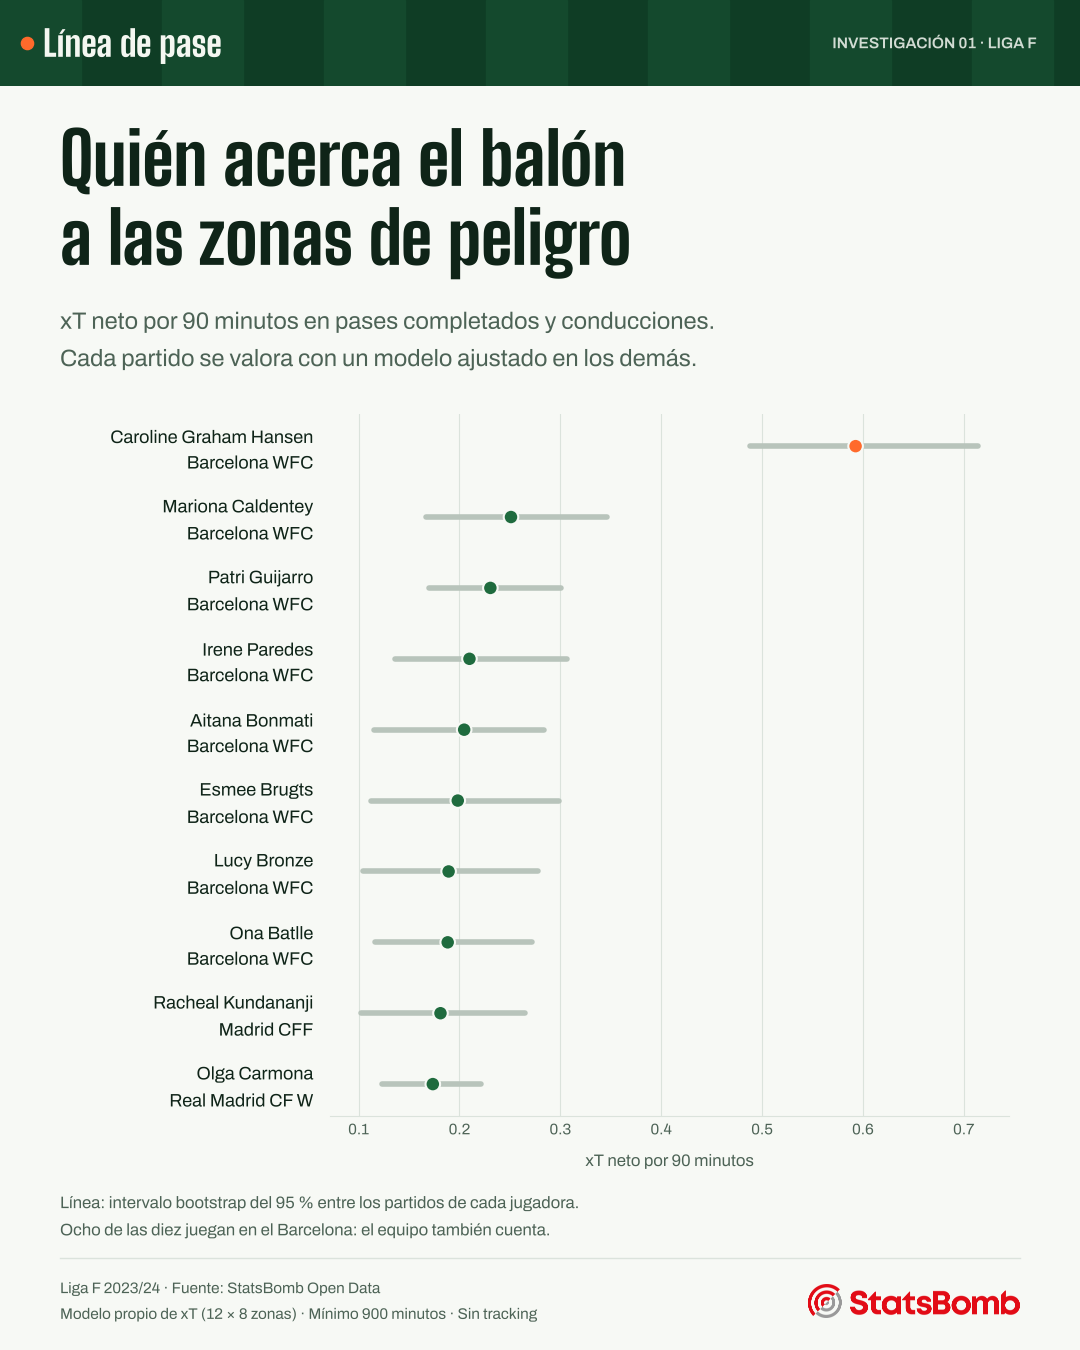

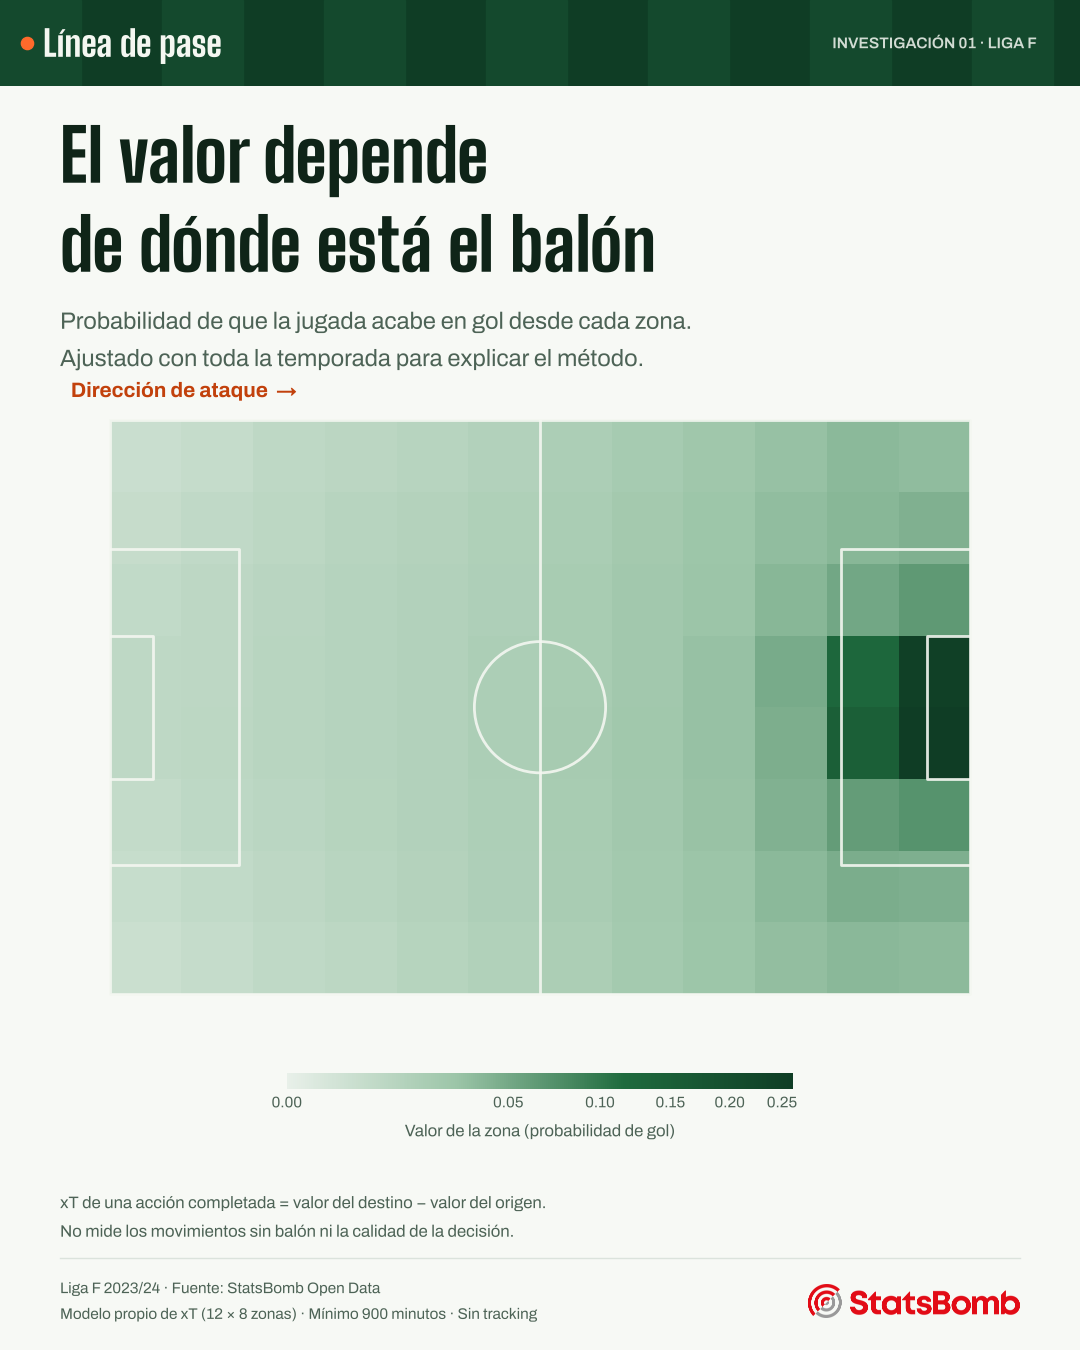

In [6]:
validacion = json.loads((RAIZ / 'documentacion/validacion.json').read_text(encoding='utf-8'))
display(pd.DataFrame(validacion['sensibilidad']))
display(Image(filename=str(RAIZ / 'graficos/01_creadoras_xt_instagram.png'), width=540))
display(Image(filename=str(RAIZ / 'graficos/02_superficie_xt_instagram.png'), width=540))


## 6. Reproducción, fuentes y publicación

Para repetir las pruebas: `python -m unittest discover -s pruebas -v`. El registro de ejecución acompaña el paquete. El archivo `documentacion/manifiesto_descargas.json` identifica URLs, fechas UTC y hashes; `requirements.txt` fija las versiones utilizadas.

Datos y logo: [StatsBomb Open Data](https://github.com/hudl/open-data). [Acuerdo](https://github.com/hudl/open-data/blob/4b73468fc5b0f1950f9f66fada70ad3a4f9327cb/LICENSE.pdf). No se redistribuyen eventos ni alineaciones originales. El proveedor solicita registrar el interés; no se ha enviado información personal del usuario. No hay publicación automática.

Referencias metodológicas: [Karun Singh](https://karun.in/blog/expected-threat.html) y [socceraction](https://socceraction.readthedocs.io/en/latest/documentation/valuing_actions/xT.html). La implementación empírica de este estudio está en `codigo/modelo.py`.

Las imágenes y los textos de redes son propuestas para revisión. No se usan fotografías ni se asume que las jugadoras continúen en los clubes de 2023/24.
